### 실습 1

In [1]:
# %%writefile step1_data_generation.py
"""
파일명: step1_data_generation.py
설명: 고객 구매 데이터 생성, CSV 저장 및 데이터 탐색 실습
필요 라이브러리: pandas, numpy
설치 명령어: pip install pandas numpy
실행 방법: python step1_data_generation.py
"""

import numpy as np
import pandas as pd

# 1. 재현성을 위한 랜덤 시드 설정
np.random.seed(42)

# 2. 기초 샘플 데이터 정의
num_records = 100
names = [
    '김철수', '이영희', '박민수', '최지우', '정다은',
    '강동원', '윤서아', '임도윤', '한지민', '송중기'
]
categories = ['전자기기', '의류', '식품', '도서', '생활용품']

# 3. 정상 데이터 생성
order_ids = [f'ORD-{1000 + i}' for i in range(num_records)]
customer_names = [np.random.choice(names) for _ in range(num_records)]
ages = np.random.randint(20, 65, size=num_records).astype(object)
purchase_amounts = np.random.randint(10000, 500000, size=num_records).astype(object)

# 2024년 1월 ~ 3월 사이의 날짜 생성 (문자열 형태)
start_date = pd.to_datetime('2024-01-01')
end_date = pd.to_datetime('2024-03-31')
date_range_days = (end_date - start_date).days
order_dates = [
    (start_date + pd.Timedelta(days=int(np.random.randint(0, date_range_days)))).strftime('%Y-%m-%d')
    for _ in range(num_records)
]
selected_categories = [np.random.choice(categories) for _ in range(num_records)]

# 데이터프레임 초기화
df = pd.DataFrame({
    'order_id': order_ids,
    'customer_name': customer_names,
    'age': ages,
    'purchase_amount': purchase_amounts,
    'order_date': order_dates,
    'category': selected_categories
})

# 4. 의도적인 이상 데이터 및 결측치 삽입
# (1) 결측치(NaN/None) 삽입
df.loc[[5, 23, 50], 'customer_name'] = None      # 이름 결측치
df.loc[[12, 45, 80], 'age'] = np.nan              # 나이 결측치
df.loc[[18, 67], 'purchase_amount'] = np.nan      # 구매 금액 결측치
df.loc[[30, 75], 'category'] = None             # 카테고리 결측치

# (2) 비정상적인 나이 (음수 나이, 999세 등)
df.loc[8, 'age'] = -5
df.loc[35, 'age'] = 999

# (3) 비정상적인 구매 금액 (음수 금액, 비정상적 고액)
df.loc[15, 'purchase_amount'] = -30000
df.loc[70, 'purchase_amount'] = 99999999

# (4) 잘못된 날짜 형식 (월/일 범위 초과, 오타)
df.loc[22, 'order_date'] = '2024-02-31'   # 존재하지 않는 날짜
df.loc[48, 'order_date'] = '2024-99-99'   # 잘못된 월/일
df.loc[62, 'order_date'] = 'not_a_date'    # 텍스트 오기입

# (5) 중복 데이터 추가 (특정 행을 그대로 복사하여 덧붙임)
duplicate_rows = df.iloc[[10, 25, 40]].copy()
df = pd.concat([df, duplicate_rows], ignore_index=True)

print(f"생성된 전체 데이터 건수(중복 포함): {len(df)}건")

# 5. CSV 파일로 저장
csv_filename = 'customer_orders.csv'
df.to_csv(csv_filename, index=False, encoding='utf-8-sig')
print(f"'{csv_filename}' 파일 저장 완료!\n")

# 6. CSV 파일 다시 읽기 및 데이터 탐색
print("=" * 50)
print("데이터 읽기 및 기본 정보 탐색")
print("=" * 50)

loaded_df = pd.read_csv(csv_filename)

# (1) 행과 열 개수
print(f"1. 행/열 개수: {loaded_df.shape[0]}행 x {loaded_df.shape[1]}열")

# (2) 컬럼명
print(f"2. 컬럼 목록: {list(loaded_df.columns)}")

# (3) 데이터 자료형 및 결측치 현황 요약
print("\n3. 데이터 자료형 및 결측치 정보:")
print(loaded_df.info())

# (4) 상위 5개 행 출력
print("\n4. 상위 5개 행:")
display(loaded_df.head())

# (5) 기초 통계량 (수치형 컬럼 요약)
print("\n5. 수치형 컬럼 기초 통계량:")
display(loaded_df.describe())

# (6) 범주형 컬럼 기초 통계량
print("\n6. 범주형 컬럼 기초 통계량:")
display(loaded_df.describe(include=['O']))

생성된 전체 데이터 건수(중복 포함): 103건
'customer_orders.csv' 파일 저장 완료!

데이터 읽기 및 기본 정보 탐색
1. 행/열 개수: 103행 x 6열
2. 컬럼 목록: ['order_id', 'customer_name', 'age', 'purchase_amount', 'order_date', 'category']

3. 데이터 자료형 및 결측치 정보:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103 entries, 0 to 102
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         103 non-null    object 
 1   customer_name    100 non-null    object 
 2   age              100 non-null    float64
 3   purchase_amount  101 non-null    float64
 4   order_date       103 non-null    object 
 5   category         101 non-null    object 
dtypes: float64(2), object(4)
memory usage: 5.0+ KB
None

4. 상위 5개 행:


,order_id,customer_name,age,purchase_amount,order_date,category
0,ORD-1000,윤서아,31.0,245167.0,2024-03-29,식품
1,ORD-1001,최지우,53.0,167381.0,2024-01-25,도서
2,ORD-1002,임도윤,52.0,490671.0,2024-01-18,의류
3,ORD-1003,정다은,42.0,204806.0,2024-03-22,의류
4,ORD-1004,윤서아,43.0,80467.0,2024-03-06,식품



5. 수치형 컬럼 기초 통계량:


,age,purchase_amount
count,100.000000,1.010000e+02
mean,52.930000,1.245206e+06
std,96.628337,9.925853e+06
min,-5.000000,-3.000000e+04
25%,32.000000,1.277960e+05
50%,46.500000,2.795440e+05
75%,56.000000,3.900020e+05
max,999.000000,1.000000e+08



6. 범주형 컬럼 기초 통계량:


,order_id,customer_name,order_date,category
count,103,100,103,101
unique,100,10,65,5
top,ORD-1025,임도윤,2024-02-02,도서
freq,2,15,6,24


### 실습 2

In [2]:
# %%writefile step2_data_diagnosis.py
"""
파일명: step2_data_diagnosis.py
설명: 고객 주문 데이터(customer_orders.csv) 품질 진단 프로그램
필요 라이브러리: pandas
"""

import pandas as pd

# 1. CSV 데이터 불러오기 (원본 데이터 유지)
file_path = 'customer_orders.csv'
df = pd.read_csv(file_path)

print("=" * 60)
print("[1] 데이터 기본 정보 및 컬럼별 자료형")
print("=" * 60)
dtypes_df = pd.DataFrame({
    '컬럼명': df.columns,
    '데이터타입': [str(t) for t in df.dtypes]
})
display(dtypes_df)


# 2. 컬럼별 결측치(NaN/None) 개수 및 비율 계산
print("\n" + "=" * 60)
print("[2] 컬럼별 결측치 현황")
print("=" * 60)
null_counts = df.isnull().sum()
null_ratio = (null_counts / len(df)) * 100

missing_report = pd.DataFrame({
    '결측치 수(건)': null_counts,
    '결측 비율(%)': null_ratio.round(2)
})
display(missing_report)


# 3. 중복 데이터 확인
print("\n" + "=" * 60)
print("[3] 중복 행 및 중복 주문번호 탐지")
print("=" * 60)

# 전체 행 기준 완전 중복 탐지
duplicate_rows = df[df.duplicated(keep=False)]
print(f"* 완전 중복된 행 개수: {df.duplicated().sum()}건 (관련 전체 행: {len(duplicate_rows)}건)")

# 주문번호(order_id) 중복 탐지
dup_order_ids = df[df.duplicated(subset=['order_id'], keep=False)]
print(f"* 중복된 주문번호(order_id) 건수: {df.duplicated(subset=['order_id']).sum()}건")
if not dup_order_ids.empty:
    print("\n[중복 주문번호 데이터 목록]")
    display(dup_order_ids.sort_values(by='order_id'))


# 4. 이상치 및 유효성 진단 (나이, 구매금액, 날짜, 비숫자)
print("\n" + "=" * 60)
print("[4] 세부 데이터 유효성 검사")
print("=" * 60)

# (1) 비정상 나이 탐지: 나이가 0세 미만이거나 120세 초과
abnormal_age = df[(df['age'] < 0) | (df['age'] > 120)]
print(f"\n(1) 비정상 나이 (0세 미만 또는 120세 초과): {len(abnormal_age)}건")
display(abnormal_age)

# (2) 구매 금액 음수 탐지
# 수치형 변환 시도 (문자열 포함 가능성 대비 errors='coerce')
purchase_num = pd.to_numeric(df['purchase_amount'], errors='coerce')
negative_purchase = df[purchase_num < 0]
print(f"\n(2) 음수 구매 금액: {len(negative_purchase)}건")
display(negative_purchase)

# (3) 구매 금액에 숫자가 아닌 문자가 포함된 행 탐지 (결측치는 제외)
# to_numeric 결과가 NaN이지만 원본은 null이 아니었던 경우 = 문자/오류 입력
non_numeric_purchase = df[purchase_num.isna() & df['purchase_amount'].notna()]
print(f"\n(3) 구매 금액에 숫자가 아닌 문자 포함: {len(non_numeric_purchase)}건")
display(non_numeric_purchase)

# (4) 잘못된 날짜 형식 탐지 (결측치는 제외)
parsed_dates = pd.to_datetime(df['order_date'], errors='coerce')
invalid_dates = df[parsed_dates.isna() & df['order_date'].notna()]
print(f"\n(4) 날짜 형식 오류(존재하지 않거나 변환 불가): {len(invalid_dates)}건")
display(invalid_dates)


# 5. 진단 결과 종합 요약 테이블 생성 및 CSV 저장
print("\n" + "=" * 60)
print("[5] 진단 결과 종합 요약 및 CSV 저장")
print("=" * 60)

diagnosis_summary = [
    {"진단 항목": "전체 행 개수", "이상 건수": len(df), "비고": "전체 레코드 수"},
    {"진단 항목": "결측치 포함 행 수", "이상 건수": df.isnull().any(axis=1).sum(), "비고": "하나 이상의 컬럼이 NaN"},
    {"진단 항목": "완전 중복 행 수", "이상 건수": df.duplicated().sum(), "비고": "모든 컬럼 동일"},
    {"진단 항목": "주문번호(order_id) 중복", "이상 건수": df.duplicated(subset=['order_id']).sum(), "비고": "고유해야 할 식별자 중복"},
    {"진단 항목": "비정상 나이 (<0 또는 >120)", "이상 건수": len(abnormal_age), "비고": "유효 연령 범위 초과/미만"},
    {"진단 항목": "음수 구매 금액", "이상 건수": len(negative_purchase), "비고": "0원 미만의 금액"},
    {"진단 항목": "구매 금액 비숫자 문자 포함", "이상 건수": len(non_numeric_purchase), "비고": "숫자 변환 실패 데이터"},
    {"진단 항목": "날짜 형식 오류", "이상 건수": len(invalid_dates), "비고": "ISO 포맷 불일치 또는 존재하지 않는 날짜"}
]

diagnosis_df = pd.DataFrame(diagnosis_summary)
display(diagnosis_df)

# 진단 결과 CSV 저장
output_filename = 'preprocessing_diagnosis.csv'
diagnosis_df.to_csv(output_filename, index=False, encoding='utf-8-sig')
print(f"\n'{output_filename}' 저장이 완료되었습니다.")

[1] 데이터 기본 정보 및 컬럼별 자료형


,컬럼명,데이터타입
0,order_id,object
1,customer_name,object
2,age,float64
3,purchase_amount,float64
4,order_date,object
5,category,object



[2] 컬럼별 결측치 현황


,결측치 수(건),결측 비율(%)
order_id,0,0.00
customer_name,3,2.91
age,3,2.91
purchase_amount,2,1.94
order_date,0,0.00
category,2,1.94



[3] 중복 행 및 중복 주문번호 탐지
* 완전 중복된 행 개수: 3건 (관련 전체 행: 6건)
* 중복된 주문번호(order_id) 건수: 3건

[중복 주문번호 데이터 목록]


...


(4) 날짜 형식 오류(존재하지 않거나 변환 불가): 3건


,order_id,customer_name,age,purchase_amount,order_date,category
22,ORD-1022,송중기,46.0,428400.0,2024-02-31,도서
48,ORD-1048,윤서아,61.0,283255.0,2024-99-99,전자기기
62,ORD-1062,이영희,20.0,130975.0,not_a_date,도서



[5] 진단 결과 종합 요약 및 CSV 저장


,진단 항목,이상 건수,비고
0,전체 행 개수,103,전체 레코드 수
1,결측치 포함 행 수,10,하나 이상의 컬럼이 NaN
2,완전 중복 행 수,3,모든 컬럼 동일
3,주문번호(order_id) 중복,3,고유해야 할 식별자 중복
4,비정상 나이 (<0 또는 >120),2,유효 연령 범위 초과/미만
5,음수 구매 금액,1,0원 미만의 금액
6,구매 금액 비숫자 문자 포함,0,숫자 변환 실패 데이터
7,날짜 형식 오류,3,ISO 포맷 불일치 또는 존재하지 않는 날짜



'preprocessing_diagnosis.csv' 저장이 완료되었습니다.


### 실습 3

In [3]:
# %%writefile step3_data_cleaning.py
"""
파일명: step3_data_cleaning.py
설명: 고객 구매 데이터 정제 및 오류 데이터 격리 파이프라인
필요 라이브러리: pandas, numpy
"""

import numpy as np
import pandas as pd

# ===================================================================
# 0. 데이터 로드 및 초기 상태 기록 (원본 보존)
# ===================================================================
file_path = 'customer_orders.csv'
raw_df = pd.read_csv(file_path)
df = raw_df.copy()

print("=" * 65)
print("[0] 원본 데이터 로드 완료")
print(f"* 원본 데이터 건수: {len(df)}행")
print("=" * 65)

# 전후 비교를 위한 정제 전 통계 저장
before_stats = {
    '행 수': len(df),
    '완전 중복 행': df.duplicated().sum(),
    '주문번호 중복': df.duplicated(subset=['order_id']).sum(),
    '결측치 합계': df.isnull().sum().to_dict()
}

# ===================================================================
# 1. 문자열 앞뒤 공백 제거 (고객명, 상품 카테고리)
# ===================================================================
print("\n[1] 문자열 공백 제거")
for col in ['customer_name', 'category']:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()
        # 문자열 'None', 'nan'으로 바뀐 결측치를 다시 실제 np.nan으로 복구
        df[col] = df[col].replace({'None': np.nan, 'nan': np.nan, '': np.nan})

# ===================================================================
# 2 & 3. 중복 데이터 처리
# 정책 1) 모든 컬럼 값이 완전히 동일한 중복 행은 중복 입력으로 판단하여 1건만 유지
# 정책 2) 주문번호(order_id)만 겹치는 경우, 첫 번째 입력 건을 보존하고 이후 건은 제거
# ===================================================================
print("\n[2 & 3] 중복 행 및 주문번호 중복 처리")
init_len = len(df)
# (1) 완전 중복 제거
df = df.drop_duplicates(keep='first').reset_index(drop=True)
print(f"* 완전 중복 행 {init_len - len(df)}건 제거 완료 (남은 행: {len(df)}건)")

# (2) 주문번호 중복 검증 및 정책 적용
order_id_dup_mask = df.duplicated(subset=['order_id'], keep=False)
if order_id_dup_mask.any():
    print("* 주문번호(order_id) 중복 데이터 확인:")
    display(df[order_id_dup_mask].sort_values(by='order_id'))
    # 정책: 최초 발생 주문(첫 번째 레코드)을 유효 주문으로 인정
    df = df.drop_duplicates(subset=['order_id'], keep='first').reset_index(drop=True)
    print(f"* 주문번호 중복 건 정리 완료 (남은 행: {len(df)}건)")

# ===================================================================
# 4. 숫자형 변환 및 특수문자(쉼표, '원', 공백 등) 처리
# ===================================================================
print("\n[4] 수치형 변환")
# (1) 구매 금액 특수문자 제거 후 float 변환
df['purchase_amount'] = (
    df['purchase_amount']
    .astype(str)
    .str.replace(r'[^0-9.-]', '', regex=True)  # 숫자, '-', '.' 제외 모두 제거
    .replace('', np.nan)
    .astype(float)
)

# (2) 나이 수치형 변환
df['age'] = pd.to_numeric(df['age'], errors='coerce')

# ===================================================================
# 5. 날짜 형식 변환 및 유효하지 않은 날짜 결측치(NaT) 처리
# ===================================================================
print("\n[5] 날짜 형식 변환 (잘못된 형식 -> NaT)")
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')

# ===================================================================
# 6. 비정상 나이 탐지 및 결측치 처리 (0세 미만, 120세 초과)
# ===================================================================
print("\n[6] 비정상 나이 탐지 및 NaN 변환")
abnormal_age_mask = (df['age'] < 0) | (df['age'] > 120)
print(f"* 비정상 나이 건수: {abnormal_age_mask.sum()}건")
if abnormal_age_mask.any():
    display(df[abnormal_age_mask][['order_id', 'customer_name', 'age']])
    df.loc[abnormal_age_mask, 'age'] = np.nan

# ===================================================================
# 7. 음수 구매 금액 분리 (삭제하지 않고 별도 rejected_data로 격리)
# ===================================================================
print("\n[7] 음수 구매 금액 분리 및 격리")
negative_purchase_mask = df['purchase_amount'] < 0
rejected_data = df[negative_purchase_mask].copy()
rejected_data['rejection_reason'] = '음수 구매 금액 오류'

# 정상 데이터셋에서는 제외
clean_df = df[~negative_purchase_mask].copy().reset_index(drop=True)
print(f"* 격리된 음수 금액 건수: {len(rejected_data)}건")
display(rejected_data)

# ===================================================================
# 8. 변수별 결측치 처리 정책 적용
# 정책 1) 나이(age): 이상치 영향이 적은 '중앙값(median)'으로 대체
# 정책 2) 고객명(customer_name), 카테고리(category): '알수없음'으로 대체
# 정책 3) 주문일자(order_date): 주문 시점 왜곡 방지를 위해 임의 추정하지 않고 '결측(NaT) 유지'
# 정책 4) 구매금액(purchase_amount): 매출 왜곡을 피하기 위해 대체를 보류하고 결측 유지
# ===================================================================
print("\n[8] 변수별 결측치 정책 적용")
age_median = clean_df['age'].median()
print(f"* 나이 결측치 대체값(중앙값): {age_median:.1f}세")
clean_df['age'] = clean_df['age'].fillna(age_median)

clean_df['customer_name'] = clean_df['customer_name'].fillna('알수없음')
clean_df['category'] = clean_df['category'].fillna('기타/미분류')

# ===================================================================
# 9. 정제 전후 비교 및 데이터 무결성 검증
# ===================================================================
print("\n" + "=" * 65)
print("[9] 정제 전후 지표 비교")
print("=" * 65)

after_stats = {
    '행 수': len(clean_df),
    '완전 중복 행': clean_df.duplicated().sum(),
    '주문번호 중복': clean_df.duplicated(subset=['order_id']).sum(),
    '결측치 합계': clean_df.isnull().sum().to_dict()
}

comparison_summary = pd.DataFrame({
    '지표': ['총 행 수', '완전 중복 행 수', '주문번호 중복 수', '격리된 오류 데이터 수'],
    '정제 전': [before_stats['행 수'], before_stats['완전 중복 행'], before_stats['주문번호 중복'], 0],
    '정제 후': [after_stats['행 수'], after_stats['완전 중복 행'], after_stats['주문번호 중복'], len(rejected_data)]
})
display(comparison_summary)

null_compare_df = pd.DataFrame({
    '정제 전 결측치': before_stats['결측치 합계'],
    '정제 후 결측치': after_stats['결측치 합계']
})
print("\n[컬럼별 결측치 전/후 비교]")
display(null_compare_df)

# ===================================================================
# 10. 파일 저장 (cleaned_data.csv, rejected_data.csv)
# ===================================================================
clean_df.to_csv('cleaned_data.csv', index=False, encoding='utf-8-sig')
rejected_data.to_csv('rejected_data.csv', index=False, encoding='utf-8-sig')

print("\n" + "=" * 65)
print("파일 저장 완료:")
print(f" - 정제 완료 데이터: cleaned_data.csv ({len(clean_df)}건)")
print(f" - 격리 오류 데이터: rejected_data.csv ({len(rejected_data)}건)")
print("=" * 65)

# 최종 정제 데이터 샘플 미리보기
display(clean_df.head())

[0] 원본 데이터 로드 완료
* 원본 데이터 건수: 103행

[1] 문자열 공백 제거

[2 & 3] 중복 행 및 주문번호 중복 처리
* 완전 중복 행 3건 제거 완료 (남은 행: 100건)

[4] 수치형 변환

[5] 날짜 형식 변환 (잘못된 형식 -> NaT)

[6] 비정상 나이 탐지 및 NaN 변환
* 비정상 나이 건수: 2건


,order_id,customer_name,age
8,ORD-1008,임도윤,-5.0
35,ORD-1035,정다은,999.0



[7] 음수 구매 금액 분리 및 격리
* 격리된 음수 금액 건수: 1건


,order_id,customer_name,age,purchase_amount,order_date,category,rejection_reason
15,ORD-1015,정다은,33.0,-30000.0,2024-02-17,생활용품,음수 구매 금액 오류



[8] 변수별 결측치 정책 적용
* 나이 결측치 대체값(중앙값): 47.0세

[9] 정제 전후 지표 비교


,지표,정제 전,정제 후
0,총 행 수,103,99
1,완전 중복 행 수,3,0
2,주문번호 중복 수,3,0
3,격리된 오류 데이터 수,0,1



[컬럼별 결측치 전/후 비교]


,정제 전 결측치,정제 후 결측치
order_id,0,0
customer_name,3,0
age,3,0
purchase_amount,2,2
order_date,0,3
category,2,0



파일 저장 완료:
 - 정제 완료 데이터: cleaned_data.csv (99건)
 - 격리 오류 데이터: rejected_data.csv (1건)


,order_id,customer_name,age,purchase_amount,order_date,category
0,ORD-1000,윤서아,31.0,245167.0,2024-03-29,식품
1,ORD-1001,최지우,53.0,167381.0,2024-01-25,도서
2,ORD-1002,임도윤,52.0,490671.0,2024-01-18,의류
3,ORD-1003,정다은,42.0,204806.0,2024-03-22,의류
4,ORD-1004,윤서아,43.0,80467.0,2024-03-06,식품


### 실습 4

[1] 정제 데이터 로드 완료: 99건

[2] 파생 변수 생성 진행
* 파생변수가 추가된 데이터 샘플:


,order_id,customer_name,purchase_amount,customer_tier,order_month,order_day_name,age_group
0,ORD-1000,윤서아,245167.0,VIP,3.0,금,30대
1,ORD-1001,최지우,167381.0,VIP,1.0,목,기타
2,ORD-1002,임도윤,490671.0,VIP,1.0,목,기타
3,ORD-1003,정다은,204806.0,VIP,3.0,금,40대
4,ORD-1004,윤서아,80467.0,VIP,3.0,수,40대


* 'featured_customer_orders.csv' 저장 완료!

[3] 그룹별 통계 집계 및 CSV 저장

[카테고리별 집계 결과]


,category,주문건수,구매금액합계,평균구매금액,구매금액합계_원
0,기타/미분류,2,445882.0,2.229410e+05,"445,882원"
1,도서,24,6240402.0,2.836546e+05,"6,240,402원"
2,생활용품,23,104881986.0,4.560086e+06,"104,881,986원"
3,식품,11,2860512.0,2.600465e+05,"2,860,512원"
4,의류,23,6225207.0,2.706612e+05,"6,225,207원"
5,전자기기,16,4277683.0,2.673552e+05,"4,277,683원"



[월별 집계 결과]


,order_month,주문건수,구매금액합계,평균구매금액
0,1월,37,9972544.0,2.770151e+05
1,2월,36,108829823.0,3.109424e+06
2,3월,23,5286675.0,2.298554e+05


/tmp/ipykernel_60188/2707860738.py:181: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_60188/2707860738.py:181: UserWarning: Glyph 53440 (\N{HANGUL SYLLABLE TA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_60188/2707860738.py:181: UserWarning: Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_60188/2707860738.py:181: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_60188/2707860738.py:181: UserWarning: Glyph 47448 (\N{HANGUL SYLLABLE RYU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_60188/2707860738.py:181: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_60188/2707860738.py:181: UserWarning: Glyph 49436 (\N{HANGUL SYLLABLE SEO}) missing from font(s) DejaVu Sans.
  p


[4] 결측치가 집계에 미치는 영향 분석

1. 구매 금액(purchase_amount) 결측치의 영향:
   - pandas의 sum() 함수는 기본적으로 결측치(NaN)를 0으로 간주하고 계산하므로 에러는 나지 않지만,
     실제 발생했을 전체 매출 규모가 '과소평가(Underestimation)'되는 원인이 됩니다.
   - 평균(mean) 계산 시에는 NaN을 분모(건수)에서 제외하므로 객단가 왜곡은 최소화되나,
     '주문 건수'와 '결제 완료 건수' 사이의 불일치가 발생할 수 있습니다.

2. 주문일(order_date) 결측치의 영향:
   - 월별/요일별 추이 분석 시 날짜가 결측(NaT)인 행은 월 그룹핑 대상에서 누락(제외)됩니다.
   - 이로 인해 월별 매출 합계의 총합이 전체 카테고리별 매출 총합보다 작아지는 집계 불일치가 발생합니다.
   - 따라서 시계열 보고서에는 '날짜 미상' 그룹을 명시하거나 데이터 손실분을 주석으로 병기해야 합니다.

[5] 시각화 그래프 생성


/tmp/ipykernel_60188/2707860738.py:181: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_60188/2707860738.py:181: UserWarning: Glyph 54633 (\N{HANGUL SYLLABLE HAB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_60188/2707860738.py:181: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_60188/2707860738.py:181: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_60188/2707860738.py:181: UserWarning: Glyph 50948 (\N{HANGUL SYLLABLE WI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_60188/2707860738.py:181: UserWarning: Glyph 50900 (\N{HANGUL SYLLABLE WEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_60188/2707860738.py:181: UserWarning: Glyph 51452 (\N{HANGUL SYLLABLE JU}) missing from font(s) DejaVu Sans

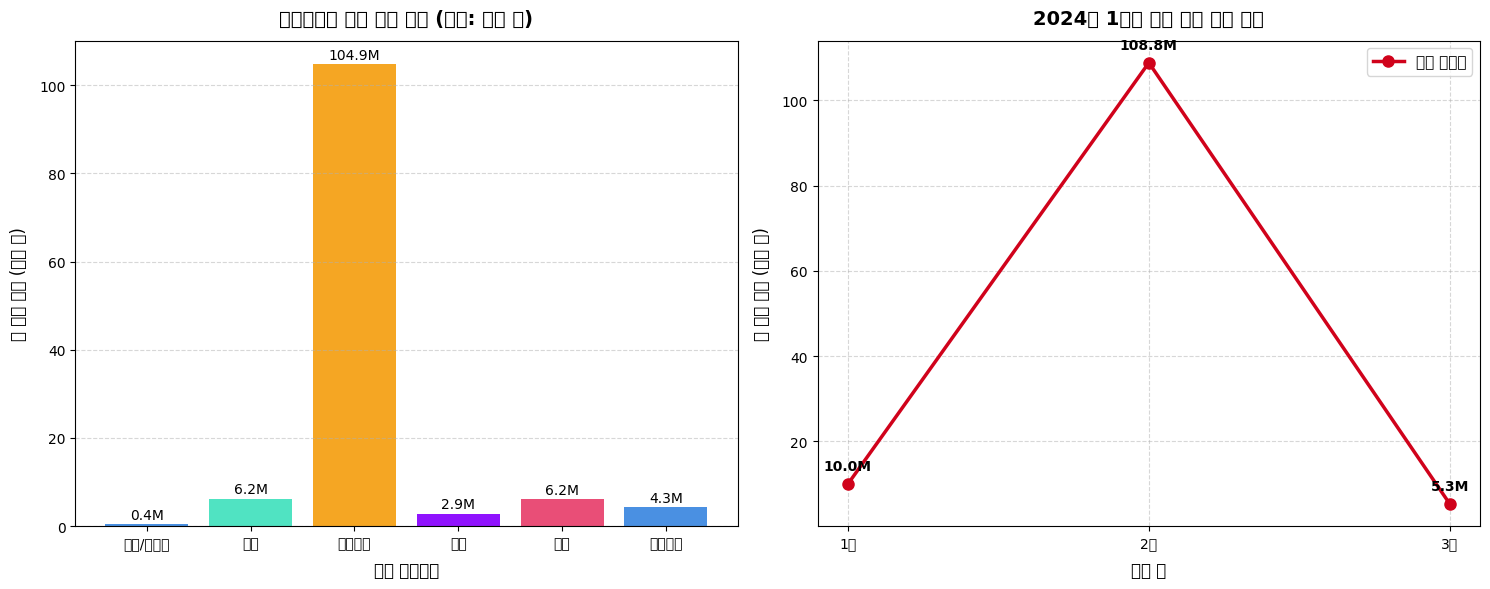

* 차트가 'sales_analysis_chart.png' 파일로 저장되었습니다.


In [4]:
# %%writefile step4_feature_engineering.py
"""
파일명: step4_feature_engineering.py
설명: 정제 데이터(cleaned_data.csv) 기반 파생변수 생성, 집계 및 시각화
필요 라이브러리: pandas, matplotlib, seaborn, koreanize_matplotlib(선택)
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------------
# 0. 한글 폰트 설정 (Colab / Windows / Mac 환경 대응)
# -------------------------------------------------------------------
import platform

if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':
    plt.rc('font', family='AppleGothic')
else:
    # 리눅스 / Colab 환경 (나눔폰트 우선 시도)
    !apt-get install -y -qq fonts-nanum > /dev/null
    import matplotlib.font_manager as fm
    font_path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
    if fm.os.path.exists(font_path):
        font_name = fm.FontProperties(fname=font_path).get_name()
        plt.rc('font', family=font_name)
plt.rc('axes', unicode_minus=False)

# -------------------------------------------------------------------
# 1. 정제 데이터 로드
# -------------------------------------------------------------------
file_path = 'cleaned_data.csv'
df = pd.read_csv(file_path)

# order_date 컬럼을 datetime 형식으로 파싱
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')

print("=" * 65)
print(f"[1] 정제 데이터 로드 완료: {len(df)}건")
print("=" * 65)

# -------------------------------------------------------------------
# 2. 파생 변수 생성
# -------------------------------------------------------------------
print("\n[2] 파생 변수 생성 진행")

# (1) 구매 금액 기준 고객 구매 등급 분류
# 30,000 미만: 일반 / 30,000 이상 70,000 미만: 우수 / 70,000 이상: VIP
def classify_tier(amount):
    if pd.isna(amount):
        return '미정/결측'
    elif amount < 30000:
        return '일반'
    elif amount < 70000:
        return '우수'
    else:
        return 'VIP'

df['customer_tier'] = df['purchase_amount'].apply(classify_tier)

# (2) 주문일에서 연도, 월, 요일 추출
df['order_year'] = df['order_date'].dt.year
df['order_month'] = df['order_date'].dt.month
# 요일 한글 변환 (월, 화, 수, 목, 금, 토, 일)
day_map = {0: '월', 1: '화', 2: '수', 3: '목', 4: '금', 5: '토', 6: '일'}
df['order_day_name'] = df['order_date'].dt.weekday.map(day_map)

# (3) 나이 구간 분류 (20대, 30대, 40대, 기타)
def classify_age_group(age):
    if pd.isna(age):
        return '미분류'
    elif 20 <= age < 30:
        return '20대'
    elif 30 <= age < 40:
        return '30대'
    elif 40 <= age < 50:
        return '40대'
    else:
        return '기타'

df['age_group'] = df['age'].apply(classify_age_group)

print("* 파생변수가 추가된 데이터 샘플:")
display(df[['order_id', 'customer_name', 'purchase_amount', 'customer_tier', 'order_month', 'order_day_name', 'age_group']].head())

# 파생 변수가 포함된 분석용 전체 데이터셋 저장
df.to_csv('featured_customer_orders.csv', index=False, encoding='utf-8-sig')
print("* 'featured_customer_orders.csv' 저장 완료!")

# -------------------------------------------------------------------
# 3. 그룹별 통계 집계
# -------------------------------------------------------------------
print("\n" + "=" * 65)
print("[3] 그룹별 통계 집계 및 CSV 저장")
print("=" * 65)

# (1) 카테고리별 주문 건수와 구매 금액 합계
category_summary = df.groupby('category').agg(
    주문건수=('order_id', 'count'),
    구매금액합계=('purchase_amount', 'sum'),
    평균구매금액=('purchase_amount', 'mean')
).reset_index()

category_summary['구매금액합계_원'] = category_summary['구매금액합계'].apply(lambda x: f"{x:,.0f}원")
print("\n[카테고리별 집계 결과]")
display(category_summary)
category_summary.to_csv('summary_by_category.csv', index=False, encoding='utf-8-sig')

# (2) 월별 구매 금액 합계 및 주문 건수 (날짜 결측 제외)
monthly_summary = df.dropna(subset=['order_month']).groupby('order_month').agg(
    주문건수=('order_id', 'count'),
    구매금액합계=('purchase_amount', 'sum'),
    평균구매금액=('purchase_amount', 'mean')
).reset_index()
monthly_summary['order_month'] = monthly_summary['order_month'].astype(int).astype(str) + '월'

print("\n[월별 집계 결과]")
display(monthly_summary)
monthly_summary.to_csv('summary_by_month.csv', index=False, encoding='utf-8-sig')

# -------------------------------------------------------------------
# 4. 집계 과정에서 결측치가 미치는 영향 설명
# -------------------------------------------------------------------
print("\n" + "=" * 65)
print("[4] 결측치가 집계에 미치는 영향 분석")
print("=" * 65)
missing_effects = """
1. 구매 금액(purchase_amount) 결측치의 영향:
   - pandas의 sum() 함수는 기본적으로 결측치(NaN)를 0으로 간주하고 계산하므로 에러는 나지 않지만,
     실제 발생했을 전체 매출 규모가 '과소평가(Underestimation)'되는 원인이 됩니다.
   - 평균(mean) 계산 시에는 NaN을 분모(건수)에서 제외하므로 객단가 왜곡은 최소화되나,
     '주문 건수'와 '결제 완료 건수' 사이의 불일치가 발생할 수 있습니다.

2. 주문일(order_date) 결측치의 영향:
   - 월별/요일별 추이 분석 시 날짜가 결측(NaT)인 행은 월 그룹핑 대상에서 누락(제외)됩니다.
   - 이로 인해 월별 매출 합계의 총합이 전체 카테고리별 매출 총합보다 작아지는 집계 불일치가 발생합니다.
   - 따라서 시계열 보고서에는 '날짜 미상' 그룹을 명시하거나 데이터 손실분을 주석으로 병기해야 합니다.
"""
print(missing_effects)

# -------------------------------------------------------------------
# 5. Matplotlib 시각화 (한글 제목 및 축 이름 적용)
# -------------------------------------------------------------------
print("=" * 65)
print("[5] 시각화 그래프 생성")
print("=" * 65)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 그래프 1: 카테고리별 구매 금액 합계 (막대그래프)
colors = ['#4A90E2', '#50E3C2', '#F5A623', '#9013FE', '#E94E77']
bars = axes[0].bar(category_summary['category'], category_summary['구매금액합계'] / 1e6, color=colors[:len(category_summary)])
axes[0].set_title('카테고리별 구매 금액 합계 (단위: 백만 원)', fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel('상품 카테고리', fontsize=12, labelpad=8)
axes[0].set_ylabel('총 구매 금액 (백만 원)', fontsize=12, labelpad=8)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# 막대 위에 금액 수치 라벨 표기
for bar in bars:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height + 0.5,
                 f'{height:.1f}M', ha='center', va='bottom', fontsize=10)

# 그래프 2: 월별 구매 금액 추이 (꺾은선 그래프)
axes[1].plot(monthly_summary['order_month'], monthly_summary['구매금액합계'] / 1e6,
            marker='o', markersize=8, linewidth=2.5, color='#D0021B', label='월별 총매출')
axes[1].set_title('2024년 1분기 월별 구매 금액 추이', fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel('주문 월', fontsize=12, labelpad=8)
axes[1].set_ylabel('총 구매 금액 (백만 원)', fontsize=12, labelpad=8)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='upper right', fontsize=11)

# 데이터 포인트 라벨 표기
for i, row in monthly_summary.iterrows():
    axes[1].annotate(f"{row['구매금액합계']/1e6:.1f}M",
                    (row['order_month'], row['구매금액합계']/1e6),
                    textcoords="offset points", xytext=(0, 10), ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('sales_analysis_chart.png', dpi=300)
plt.show()
print("* 차트가 'sales_analysis_chart.png' 파일로 저장되었습니다.")

### 실습 5

In [7]:
# %%writefile preprocessing_app.py
"""
파일명: preprocessing_app.py
설명: 고객 구매 데이터 종합 전처리 파이프라인 애플리케이션
     (진단 -> 정제 -> 파생변수 생성 -> 격리 -> 검증 -> 리포트 생성)
필요 라이브러리: pandas, numpy
실행 방법:
    python preprocessing_app.py --input customer_orders.csv
"""

import os
import sys
import argparse
import numpy as np
import pandas as pd
from datetime import datetime


# ===================================================================
# 1. 파일 검증 및 로드 함수
# ===================================================================
def load_data(file_path: str, required_cols: list) -> pd.DataFrame:
    """입력 파일의 존재 여부와 필수 컬럼 포함 여부를 검증하고 데이터프레임을 반환합니다."""
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"[오류] 입력 파일 '{file_path}'을(를) 찾을 수 없습니다. 경로를 확인해 주세요.")

    try:
        df = pd.read_csv(file_path)
    except Exception as e:
        raise IOError(f"[오류] CSV 파일을 읽는 중 문제가 발생했습니다: {e}")

    # 필수 컬럼 누락 여부 검증
    missing_cols = [col for col in required_cols if col not in df.columns]
    if missing_cols:
        raise ValueError(f"[오류] 필수 컬럼이 누락되었습니다: {missing_cols}\n필요한 컬럼 목록: {required_cols}")

    print(f"[*] 파일 로드 성공: '{file_path}' (총 {len(df)}건)")
    return df


# ===================================================================
# 2. 데이터 품질 진단 함수
# ===================================================================
def diagnose_data(df: pd.DataFrame) -> dict:
    """데이터 품질 이상(결측치, 중복, 비정상 나이, 음수 금액, 날짜 오류)을 진단합니다."""
    print("\n[*] 데이터 품질 진단을 시작합니다...")

    total_rows = len(df)
    null_counts = df.isnull().sum().to_dict()
    full_dups = int(df.duplicated().sum())
    order_id_dups = int(df.duplicated(subset=['order_id']).sum()) if 'order_id' in df.columns else 0

    # 비정상 나이 (0세 미만 또는 120세 초과)
    age_numeric = pd.to_numeric(df['age'], errors='coerce')
    abnormal_age_cnt = int(((age_numeric < 0) | (age_numeric > 120)).sum())

    # 음수 구매 금액
    purchase_numeric = pd.to_numeric(df['purchase_amount'].astype(str).str.replace(r'[^0-9.-]', '', regex=True), errors='coerce')
    negative_purchase_cnt = int((purchase_numeric < 0).sum())

    # 날짜 형식 오류
    parsed_dates = pd.to_datetime(df['order_date'], errors='coerce')
    invalid_date_cnt = int((parsed_dates.isna() & df['order_date'].notna()).sum())

    diagnosis_result = {
        'total_rows': total_rows,
        'null_counts': null_counts,
        'full_duplicates': full_dups,
        'order_id_duplicates': order_id_dups,
        'abnormal_age_count': abnormal_age_cnt,
        'negative_purchase_count': negative_purchase_cnt,
        'invalid_date_count': invalid_date_cnt
    }
    print(f"  - 완전 중복 행: {full_dups}건, 주문번호 중복: {order_id_dups}건")
    print(f"  - 비정상 나이: {abnormal_age_cnt}건, 음수 금액: {negative_purchase_cnt}건, 날짜 오류: {invalid_date_cnt}건")
    return diagnosis_result


# ===================================================================
# 3. 데이터 정제 및 오류 데이터 격리 함수
# ===================================================================
def clean_data(raw_df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    정제 규칙에 따라 데이터를 전처리하고 정상 데이터와 격리 데이터를 분리 반환합니다.
    """
    print("\n[*] 데이터 정제 및 이상치 처리를 진행합니다...")
    df = raw_df.copy()

    # 1) 문자열 앞뒤 공백 제거
    for col in ['customer_name', 'category']:
        if col in df.columns:
            df[col] = df[col].astype(str).str.strip()
            df[col] = df[col].replace({'None': np.nan, 'nan': np.nan, '': np.nan})

    # 2) 중복 행 제거 (완전 중복 및 주문번호 중복: 최초 발생 건 보존)
    df = df.drop_duplicates(keep='first').reset_index(drop=True)
    if 'order_id' in df.columns:
        df = df.drop_duplicates(subset=['order_id'], keep='first').reset_index(drop=True)

    # 3) 수치형 변환
    df['purchase_amount'] = (
        df['purchase_amount']
        .astype(str)
        .str.replace(r'[^0-9.-]', '', regex=True)
        .replace('', np.nan)
        .astype(float)
    )
    df['age'] = pd.to_numeric(df['age'], errors='coerce')

    # 4) 날짜 형식 변환 (잘못된 형식은 NaT 변환)
    df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')

    # 5) 비정상 나이 NaN 처리 (0 미만, 120 초과)
    abnormal_age_mask = (df['age'] < 0) | (df['age'] > 120)
    df.loc[abnormal_age_mask, 'age'] = np.nan

    # 6) 음수 구매 금액 분리 및 격리 (삭제하지 않고 rejected_df로 이동)
    negative_mask = df['purchase_amount'] < 0
    rejected_df = df[negative_mask].copy()
    rejected_df['rejection_reason'] = '음수 구매 금액 오류 (0원 미만)'

    # 정상 데이터셋 슬라이싱
    cleaned_df = df[~negative_mask].copy().reset_index(drop=True)

    # 7) 결측치 정책 적용
    # 나이: 중앙값 대체
    age_median = cleaned_df['age'].median()
    cleaned_df['age'] = cleaned_df['age'].fillna(age_median)
    # 범주형/식별자: 명시적 라벨 대체
    cleaned_df['customer_name'] = cleaned_df['customer_name'].fillna('알수없음')
    cleaned_df['category'] = cleaned_df['category'].fillna('기타/미분류')
    # order_date, purchase_amount: 왜곡 방지를 위해 결측 유지

    print(f"  - 정제 완료 건수: {len(cleaned_df)}건 / 격리된 오류 건수: {len(rejected_df)}건")
    return cleaned_df, rejected_df


# ===================================================================
# 4. 분석용 파생 변수 생성 함수
# ===================================================================
def generate_features(df: pd.DataFrame) -> pd.DataFrame:
    """분석에 필요한 파생 변수(고객 등급, 주문 년/월/요일, 연령대 구간)를 생성합니다."""
    print("\n[*] 분석용 파생 변수를 생성합니다...")
    featured_df = df.copy()

    # (1) 고객 구매 등급
    def tier_mapper(amount):
        if pd.isna(amount):
            return '미정/결측'
        elif amount < 30000:
            return '일반'
        elif amount < 70000:
            return '우수'
        else:
            return 'VIP'
    featured_df['customer_tier'] = featured_df['purchase_amount'].apply(tier_mapper)

    # (2) 주문 날짜 파생변수
    featured_df['order_year'] = featured_df['order_date'].dt.year
    featured_df['order_month'] = featured_df['order_date'].dt.month
    day_names = {0: '월', 1: '화', 2: '수', 3: '목', 4: '금', 5: '토', 6: '일'}
    featured_df['order_day_name'] = featured_df['order_date'].dt.weekday.map(day_names)

    # (3) 연령대 구간
    def age_group_mapper(age):
        if pd.isna(age):
            return '미분류'
        elif 20 <= age < 30:
            return '20대'
        elif 30 <= age < 40:
            return '30대'
        elif 40 <= age < 50:
            return '40대'
        else:
            return '기타'
    featured_df['age_group'] = featured_df['age'].apply(age_group_mapper)

    return featured_df


# ===================================================================
# 5. 전처리 결과 검증 및 보고서 작성 함수
# ===================================================================
def generate_report(raw_df: pd.DataFrame, clean_df: pd.DataFrame, rejected_df: pd.DataFrame, report_path: str = 'preprocessing_report.txt'):
    """정제 전후 비교 지표와 정책 설명을 포함한 종합 리포트를 파일로 저장합니다."""
    print(f"\n[*] 종합 전처리 보고서('{report_path}')를 생성합니다...")

    raw_nulls = raw_df.isnull().sum().to_dict()
    clean_nulls = clean_df.isnull().sum().to_dict()

    now_str = datetime.now().strftime('%Y-%m-%d %H:%M:%S')
    report_content = f"""======================================================================
                 [고객 구매 데이터 종합 전처리 보고서]
======================================================================
* 보고서 생성 일시: {now_str}

1. 데이터 건수 및 중복 비교 요약
----------------------------------------------------------------------
- 원본 전체 레코드 수    : {len(raw_df):>5}건
- 원본 완전 중복 행      : {raw_df.duplicated().sum():>5}건
- 원본 주문번호 중복     : {raw_df.duplicated(subset=['order_id']).sum():>5}건
- 정제 완료 레코드 수    : {len(clean_df):>5}건
- 격리된 오류 레코드 수  : {len(rejected_df):>5}건 (rejected_data.csv)

2. 컬럼별 결측치 전/후 비교
----------------------------------------------------------------------
"""
    for col in raw_df.columns:
        b_cnt = raw_nulls.get(col, 0)
        a_cnt = clean_nulls.get(col, 0)
        report_content += f"- {col:<18} : 정제 전 {b_cnt:>3}건 -> 정제 후 {a_cnt:>3}건\n"

    report_content += f"""
3. 결측치 및 이상치 처리 정책
----------------------------------------------------------------------
(1) 중복 데이터: 완전 중복 및 중복 주문번호는 선착순 최초 레코드 1건만 유지
(2) 나이(age): 0세 미만, 120세 초과 비정상값은 결측(NaN) 후 중앙값({clean_df['age'].median():.1f}세)으로 대체
(3) 고객명/카테고리: 결측치를 '알수없음' 및 '기타/미분류'로 보정
(4) 구매금액 음수값: 데이터 임의 삭제 없이 rejected_data.csv로 격리 보관
(5) 구매금액 결측치: 매출 과소평가/통계 왜곡 방지를 위해 결측치 유지
(6) 주문일자(order_date): 형식 오류값은 NaT(결측) 변환 후 시계열 왜곡 방지를 위해 유지

4. 생성된 저장 파일 목록
----------------------------------------------------------------------
- 정제 완료 데이터 : cleaned_data.csv
- 파생변수 포함본  : featured_customer_orders.csv
- 격리 오류 데이터 : rejected_data.csv
- 품질 진단 보고서 : preprocessing_report.txt
======================================================================
"""
    with open(report_path, 'w', encoding='utf-8') as f:
        f.write(report_content)
    print(f"  - 보고서 저장 완료: {report_path}")
    print(report_content)


# ===================================================================
# 6. 메인 실행 함수
# ===================================================================
def main(input_path: str = 'customer_orders.csv'):
    print("=" * 70)
    print("       고객 구매 데이터 자동화 전처리 애플리케이션 시작")
    print("=" * 70)

    required_columns = ['order_id', 'customer_name', 'age', 'purchase_amount', 'order_date', 'category']

    try:
        # 1. 파일 검증 및 로드
        raw_df = load_data(input_path, required_columns)

        # 2. 품질 진단
        diagnose_data(raw_df)

        # 3. 데이터 정제 및 격리
        clean_df, rejected_df = clean_data(raw_df)

        # 4. 분석용 파생 변수 생성
        featured_df = generate_features(clean_df)

        # 5. 결과 파일 저장 (원본 보존, 개별 저장)
        clean_df.to_csv('cleaned_data.csv', index=False, encoding='utf-8-sig')
        rejected_df.to_csv('rejected_data.csv', index=False, encoding='utf-8-sig')
        featured_df.to_csv('featured_customer_orders.csv', index=False, encoding='utf-8-sig')
        print("\n[*] 데이터프레임 파일 저장 완료 (cleaned_data.csv, rejected_data.csv, featured_customer_orders.csv)")

        # 6. 리포트 생성
        generate_report(raw_df, clean_df, rejected_df, report_path='preprocessing_report.txt')

        print("\n[성공] 모든 전처리 파이프라인이 정상적으로 완료되었습니다!")

    except FileNotFoundError as fnf_err:
        print(f"\n[파일 오류 발생] {fnf_err}", file=sys.stderr)
        print("[해결 방법] 파일명이 올바른지 확인하거나, 실습 1 코드를 실행하여 'customer_orders.csv'를 먼저 생성해 주세요.", file=sys.stderr)
    except ValueError as val_err:
        print(f"\n[입력 검증 오류 발생] {val_err}", file=sys.stderr)
        print("[해결 방법] CSV 파일의 헤더에 필수 컬럼이 모두 포함되어 있는지 확인해 주세요.", file=sys.stderr)
    except Exception as err:
        print(f"\n[알 수 없는 런타임 오류 발생] {err}", file=sys.stderr)
        print("[해결 방법] 입력 데이터 형식을 확인하거나 관리자에게 문의해 주세요.", file=sys.stderr)


if __name__ == '__main__':
    parser = argparse.ArgumentParser(description='온라인 쇼핑몰 데이터 전처리 애플리케이션')
    parser.add_argument('--input', type=str, default='customer_orders.csv', help='입력 CSV 파일 경로 (기본값: customer_orders.csv)')

    # Jupyter/Colab 환경에서의 예기치 않은 인자(-f ...) 무시를 위해 parse_known_args 사용
    args, _ = parser.parse_known_args()
    main(input_path=args.input)

       고객 구매 데이터 자동화 전처리 애플리케이션 시작
[*] 파일 로드 성공: 'customer_orders.csv' (총 103건)

[*] 데이터 품질 진단을 시작합니다...
  - 완전 중복 행: 3건, 주문번호 중복: 3건
  - 비정상 나이: 2건, 음수 금액: 1건, 날짜 오류: 3건

[*] 데이터 정제 및 이상치 처리를 진행합니다...
  - 정제 완료 건수: 99건 / 격리된 오류 건수: 1건

[*] 분석용 파생 변수를 생성합니다...

[*] 데이터프레임 파일 저장 완료 (cleaned_data.csv, rejected_data.csv, featured_customer_orders.csv)

[*] 종합 전처리 보고서('preprocessing_report.txt')를 생성합니다...
  - 보고서 저장 완료: preprocessing_report.txt
                 [고객 구매 데이터 종합 전처리 보고서]
* 보고서 생성 일시: 2026-10-20 08:09:59

1. 데이터 건수 및 중복 비교 요약
----------------------------------------------------------------------
- 원본 전체 레코드 수    :   103건
- 원본 완전 중복 행      :     3건
- 원본 주문번호 중복     :     3건
- 정제 완료 레코드 수    :    99건
- 격리된 오류 레코드 수  :     1건 (rejected_data.csv)

2. 컬럼별 결측치 전/후 비교
----------------------------------------------------------------------
- order_id           : 정제 전   0건 -> 정제 후   0건
- customer_name      : 정제 전   3건 -> 정제 후   0건
- age                : 정제 전   3건 -> 정제 후   0건
- purchase_a

In [8]:
# 통합 애플리케이션 실행 테스트
!python preprocessing_app.py --input customer_orders.csv

       고객 구매 데이터 자동화 전처리 애플리케이션 시작
[*] 파일 로드 성공: 'customer_orders.csv' (총 103건)

[*] 데이터 품질 진단을 시작합니다...
  - 완전 중복 행: 3건, 주문번호 중복: 3건
  - 비정상 나이: 2건, 음수 금액: 1건, 날짜 오류: 3건

[*] 데이터 정제 및 이상치 처리를 진행합니다...
  - 정제 완료 건수: 99건 / 격리된 오류 건수: 1건

[*] 분석용 파생 변수를 생성합니다...

[*] 데이터프레임 파일 저장 완료 (cleaned_data.csv, rejected_data.csv, featured_customer_orders.csv)

[*] 종합 전처리 보고서('preprocessing_report.txt')를 생성합니다...
  - 보고서 저장 완료: preprocessing_report.txt
                 [고객 구매 데이터 종합 전처리 보고서]
* 보고서 생성 일시: 2026-10-20 08:12:30

1. 데이터 건수 및 중복 비교 요약
----------------------------------------------------------------------
- 원본 전체 레코드 수    :   103건
- 원본 완전 중복 행      :     3건
- 원본 주문번호 중복     :     3건
- 정제 완료 레코드 수    :    99건
- 격리된 오류 레코드 수  :     1건 (rejected_data.csv)

2. 컬럼별 결측치 전/후 비교
----------------------------------------------------------------------
- order_id           : 정제 전   0건 -> 정제 후   0건
- customer_name      : 정제 전   3건 -> 정제 후   0건
- age                : 정제 전   3건 -> 정제 후   0건
- purchase_a